Ukuran dataset: (918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDisease
0   40   M           ATA      140.0        289.0          0     Normal  172.0              N      0.0       Up             0
1   49   F           NAP      160.0          NaN          0     Normal  156.0              N      1.0     Flat             1
2   37   M           ATA      130.0        283.0          0         ST   98.0              N      0.0       Up             0
3   48   F           ASY      138.0        214.0          0     Normal  108.0              Y      1.5     Flat             1
4   54   M           NAP      150.0        195.0          0     Normal  122.0              N      0.0       Up             0

=== Jumlah nilai unik per atribut ===
Age                50
Sex                 2
ChestPainType       4
RestingBP          67
Cholesterol       219
FastingBS           2
RestingECG          3
MaxHR             119
ExerciseA

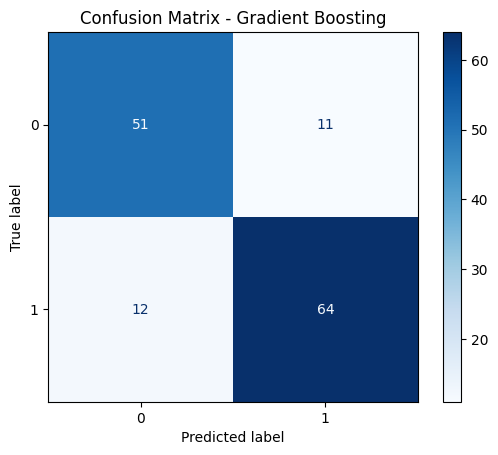


SSE              : 4390.8362
Silhouette score : 0.1972
Jumlah anggota tiap cluster:
 0    175
1    387
2    356
Name: count, dtype: int64

Cluster vs HeartDisease:
 HeartDisease    0    1
Cluster               
0              23  152
1             309   78
2              78  278

    k          SSE  Silhouette
0  2  5039.304785    0.184009
1  3  4390.836228    0.197154
2  4  4080.102775    0.146645
3  5  3854.059746    0.128899
4  6  3676.280659    0.122523
5  7  3507.502455    0.125483
6  8  3370.388180    0.122918


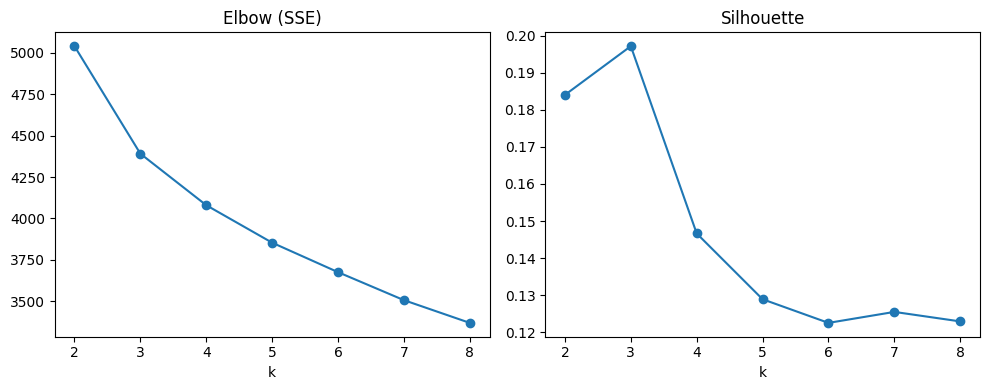

In [ ]:
"""
Nama: Dicky Ramadhan
NPM: 232310015
Kelompok: sendiri
Kombinasi algoritma & parameter yang saya gunakan:
  - Klasifikasi : GradientBoostingClassifier(n_estimators=137, learning_rate=0.07,
                  max_depth=3, subsample=0.8, random_state=88)
  - Clustering  : KMeans(n_clusters=3, n_init=17, max_iter=420, random_state=88)
"""


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score,
                             classification_report, silhouette_score)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

CSV_PATH = "/content/drive/MyDrive/Tugas Machine Learning/heart_modified.csv"

df = pd.read_csv(CSV_PATH, sep=None, engine="python")


if df["Oldpeak"].dtype == object:
    df["Oldpeak"] = pd.to_numeric(df["Oldpeak"].str.replace(",", ".", regex=False),
                                  errors="coerce")

print("Ukuran dataset:", df.shape)
print(df.head())


print("\n Jumlah nilai unik per atribut")
print(df.nunique(dropna=True))
print("\n=== Tipe data bawaan pandas ===")
print(df.dtypes)
print("\n=== Jumlah missing value per atribut ===")
print(df.isna().sum())

LABEL = "HeartDisease"
# Atribut kategorik: bertipe teks, atau numerik tetapi hanya berisi nilai biner (0/1)
cat_cols = [c for c in df.columns if c != LABEL and
            (df[c].dtype == object or df[c].nunique() <= 2)]
num_cols = [c for c in df.columns if c != LABEL and c not in cat_cols]

print("\n=== Atribut Numerik ===", num_cols)
print("=== Atribut Kategorik ===")
for c in cat_cols:
    print(f"  {c}: {sorted(df[c].dropna().unique().tolist())}")
print(f"=== Label: {LABEL} -> {sorted(df[LABEL].unique().tolist())} (kategorik biner)")


X = df.drop(columns=[LABEL])
y = df[LABEL]


print("\n=== Statistik deskriptif SEBELUM praproses (numerik) ===")
stat_before_num = X[num_cols].describe().T
print(stat_before_num)
print("\n=== Ringkasan atribut kategorik SEBELUM praproses ===")
stat_before_cat = X[cat_cols].describe(include="all").T
print(stat_before_cat)


num_imp = SimpleImputer(strategy="mean")
X_num = pd.DataFrame(num_imp.fit_transform(X[num_cols]), columns=num_cols, index=X.index)


scaler = StandardScaler()
X_num_scaled = pd.DataFrame(scaler.fit_transform(X_num), columns=num_cols, index=X.index)


cat_imp = SimpleImputer(strategy="most_frequent")
X_cat_filled = pd.DataFrame(cat_imp.fit_transform(X[cat_cols]), columns=cat_cols, index=X.index)

ohe = OneHotEncoder(drop="first", sparse_output=False)
X_cat_enc = pd.DataFrame(ohe.fit_transform(X_cat_filled),
                         columns=ohe.get_feature_names_out(cat_cols), index=X.index)

X_proc = pd.concat([X_num_scaled, X_cat_enc], axis=1)
print("\nBentuk data setelah praproses:", X_proc.shape)
print("Missing value tersisa:", int(X_proc.isna().sum().sum()))


print("\n=== Statistik deskriptif SESUDAH praproses ===")
stat_after = X_proc.describe().T
print(stat_after)


X_train, X_test, y_train, y_test = train_test_split(
    X_proc, y, test_size=0.15, random_state=88, stratify=y)
print("\nData training:", X_train.shape, "| Data testing:", X_test.shape)

clf = GradientBoostingClassifier(n_estimators=137, learning_rate=0.07, max_depth=3,
                                 subsample=0.8, random_state=88)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix:\n", cm)
print(f"Akurasi  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Presisi  : {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print("\n", classification_report(y_test, y_pred, target_names=["Sehat (0)", "Gagal Jantung (1)"]))

ConfusionMatrixDisplay(cm, display_labels=["0", "1"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Gradient Boosting")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

km = KMeans(n_clusters=3, n_init=17, max_iter=420, random_state=88)
labels = km.fit_predict(X_proc)

sse = km.inertia_
sil = silhouette_score(X_proc, labels)
print(f"\nSSE              : {sse:.4f}")
print(f"Silhouette score : {sil:.4f}")
print("Jumlah anggota tiap cluster:\n", pd.Series(labels).value_counts().sort_index())


print("\nCluster vs HeartDisease:\n", pd.crosstab(labels, y, rownames=["Cluster"], colnames=["HeartDisease"]))

ks = range(2, 9)
sse_k, sil_k = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=17, max_iter=420, random_state=88).fit(X_proc)
    sse_k.append(m.inertia_)
    sil_k.append(silhouette_score(X_proc, m.labels_))
res = pd.DataFrame({"k": list(ks), "SSE": sse_k, "Silhouette": sil_k})
print("\n", res)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(res["k"], res["SSE"], marker="o"); ax[0].set_title("Elbow (SSE)"); ax[0].set_xlabel("k")
ax[1].plot(res["k"], res["Silhouette"], marker="o"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("elbow_silhouette.png", dpi=150)
plt.show()